In [4]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [5]:
# Define transformations (Convert PIL image to Tensor and normalize)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

# Download and load Training Data
train_set = datasets.FashionMNIST(root='~/data', train=True, download=True, transform=transform)

# Download and load Test Data
test_set = datasets.FashionMNIST(root='~/data', train=False, download=True, transform=transform)

print(f"Training set size: {len(train_set)}")
print(f"Test set size: {len(test_set)}")

#Setup dataloaders for training and test sets
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

Training set size: 60000
Test set size: 10000


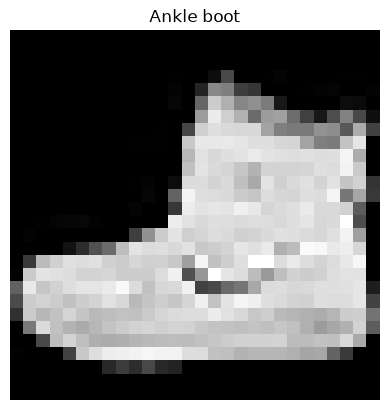

In [6]:
# Labels for the DataSet
FASHION_MNIST_CLASSES = [
    "T-shirt/top",  # Index 0
    "Trouser",      # Index 1
    "Pullover",     # Index 2
    "Dress",        # Index 3
    "Coat",         # Index 4
    "Sandal",       # Index 5
    "Shirt",        # Index 6
    "Sneaker",      # Index 7
    "Bag",          # Index 8
    "Ankle boot"    # Index 9
]

image, label = train_set[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(FASHION_MNIST_CLASSES[label])
plt.axis("off")
plt.show()

What transforms.ToTensor() does.
The transforms.ToTensor() function converts each FashionMNIST image from a PIL image into a PyTorch tensor, rearranges its dimensions to channels × height × width, and scales pixel values from 0–255 to 0.0–1.0. Each grayscale image becomes a tensor with the shape (1, 28, 28), allowing PyTorch neural networks to process the images.

Why the images are normalized.
transforms.Normalize((0.5,), (0.5,)) converts the pixel values from the [0, 1] range produced by ToTensor() to approximately [-1, 1]. Centering the data around zero gives all inputs a consistent scale, which helps gradients remain stable, improves training efficiency, and often allows the neural network to converge faster and achieve better performance. The same normalization is applied to both the training and testing datasets so the model receives data in a consistent format during training and evaluation.

Why the training data is shuffled.
The training DataLoader uses shuffle=True to reorder the training images randomly at the start of every epoch, so each mini-batch is a different, diverse mix of classes. Consecutive images in a dataset often share a class or similar features, and shuffling breaks that correlation. This prevents the model from learning patterns tied to the order of the data, keeps the gradient estimates from each batch closer to unbiased estimates of the true gradient, and encourages the model to learn general relationships between image features and clothing categories, which improves its ability to classify images it has not seen before.

Why the testing data is not shuffled.
shuffle=False is used for the test DataLoader because evaluation does not involve weight updates, making sample order irrelevant to overall metrics like loss or accuracy. Keeping the test data in a fixed order ensures fully reproducible results across runs and simplifies debugging by allowing you to easily trace predictions back to specific test indices to analyze misclassifications or build confusion matrices.